# 02 · Feature Engineering, Model Development & Experiment Tracking

**Assignment tasks covered:** Task 2 (feature engineering & model development), Task 3 (MLflow experiment tracking)
and the packaging part of Task 4.

This notebook is the *narrative* of the modelling stage. All reusable logic lives in `src/`
(`features.py`, `models.py`, `train.py`, `evaluate.py`) so that the **same code** runs here, in CI
(`python -m src.train --quick`) and inside the Docker image. The notebook calls that code rather than
re-implementing it.

| Step | What happens | Where |
|---|---|---|
| Feature engineering | impute → scale (numeric), impute → one-hot (categorical) | `src/features.py` |
| Candidate models | majority baseline, Logistic Regression, Random Forest, Gradient Boosting | `src/models.py` |
| Tuning & selection | 5-fold stratified `GridSearchCV`, selection on CV ROC-AUC | `src/train.py` |
| Tracking | parent + nested MLflow runs, params, metrics, plots, models, registry | `src/train.py` |
| Packaging | `models/heart_disease_model.joblib`, `models/mlflow_model/`, `model_metadata.json` | `src/train.py` |

In [1]:
# Project setup: find the project root so every path matches the scripts in src/
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src" / "config.py").exists():   # e.g. notebooks/ -> project root
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook from inside the project folder.")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
print(f"Project root: {ROOT} | Python {sys.version.split()[0]}")

Project root: c:\Users\Snehanjali\heart-disease-prediction-mlops | Python 3.13.5


In [2]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from src import config
from src.data import load_clean, split
from src.features import build_preprocessor
from src.models import get_candidates, make_pipeline
from src import evaluate

sns.set_theme(style="whitegrid")
PALETTE = {"No disease": "#4C78A8", "Disease": "#E4572E"}
MODEL_COLORS = {"logistic_regression": "#4C78A8", "random_forest": "#59A14F",
                "gradient_boosting": "#F28E2B", "baseline_majority": "#9AA5B1"}
FIG = config.FIGURES_DIR; FIG.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG / name, dpi=120, bbox_inches="tight")

## 1. Data and split

The cleaned file from notebook 01 is loaded through `src.data.load_clean()`, which also validates the
schema (column names, category codes, clinical ranges). The **stratified 80/20 split with `random_state=42`**
is made once; the test set is kept aside and is used only for final reporting, never for choosing a model.

In [3]:
df = load_clean()
X_train, X_test, y_train, y_test = split(df)

print("Full data:", df.shape)
print(f"Train: {X_train.shape}  disease share = {y_train.mean():.3f}")
print(f"Test:  {X_test.shape}  disease share = {y_test.mean():.3f}")
print("Missing values in train:", X_train.isna().sum()[lambda s: s > 0].to_dict())

Full data: (303, 14)
Train: (242, 13)  disease share = 0.459
Test:  (61, 13)  disease share = 0.459
Missing values in train: {'ca': 1, 'thal': 1}


## 2. Feature engineering

Decisions carried over from the EDA:

* **Numeric** (`age, trestbps, chol, thalach, oldpeak, ca`): median imputation (robust to the right skew of
  `chol` / `oldpeak`) followed by **standard scaling**, because features live on very different scales
  (chol ≈ 250 vs oldpeak ≈ 1) and the linear model's regularisation assumes comparable scales.
* **Categorical** (`sex, cp, fbs, restecg, exang, slope, thal`): most-frequent imputation and **one-hot encoding**.
  The codes are labels, not quantities (e.g. `thal` = 3/6/7), so they must not be treated as numbers.
  `handle_unknown="ignore"` means an unseen code at prediction time does not crash the API.
* Everything sits in **one `ColumnTransformer` inside each model `Pipeline`**. Cross-validation therefore
  re-fits the imputers, scaler and encoder on every training fold (no leakage), and the saved model accepts
  raw clinical values.
* **Engineered feature – `hr_pct_predicted = thalach / (220 − age)`.** Peak heart rate reached in the exercise
  test as a share of the age-predicted maximum (the standard 220 − age rule). A low value (*chronotropic
  incompetence*) is a recognised marker of heart disease, and it combines two raw features in a way a linear
  model cannot build by itself. It is added by a small stateless transformer (`ClinicalFeatures`) as the first
  pipeline step, so the API still receives the 13 raw values. Whether it actually helps is **not assumed**: it is a
  hyper-parameter (`features__add_hr_ratio`) that every model's grid search turns on and off (section 5).

In [4]:
pre = build_preprocessor()
Xt = pre.fit_transform(X_train)
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
print(f"{X_train.shape[1]} raw features  ->  {Xt.shape[1]} model features")
print(names)
display(pd.DataFrame(Xt, columns=names).describe().T[["mean", "std", "min", "max"]].round(2).head(8))

13 raw features  ->  25 model features
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'sex_0.0', 'sex_1.0', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'fbs_0.0', 'fbs_1.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'exang_0.0', 'exang_1.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


,mean,std,min,max
age,-0.00,1.00,-2.85,2.50
trestbps,-0.00,1.00,-2.10,3.93
chol,0.00,1.00,-2.35,5.96
thalach,-0.00,1.00,-3.49,2.30
oldpeak,0.00,1.00,-0.89,4.64
ca,0.00,1.00,-0.69,2.72
sex_0.0,0.32,0.47,0.00,1.00
sex_1.0,0.68,0.47,0.00,1.00


### 2b. The engineered feature in the data

Before letting the grid search decide, check that the new feature carries signal: patients with heart disease
should reach a lower share of their age-predicted maximum heart rate.

             mean    std    min    max
Diagnosis                             
Disease     0.854  0.140  0.464  1.175
No disease  0.946  0.099  0.600  1.140

Correlation with the target:
thalach (raw)                   -0.417
age (raw)                        0.223
hr_pct_predicted (engineered)   -0.359


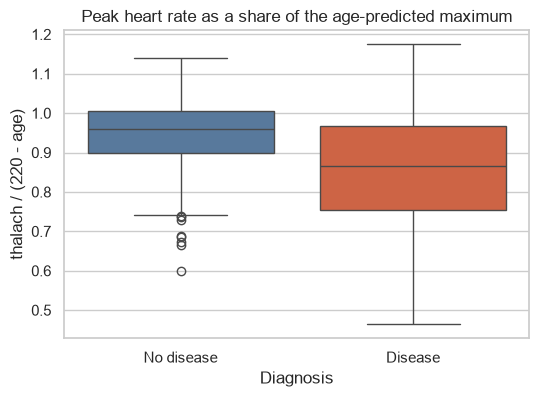

In [5]:
from src.features import ClinicalFeatures

eng = ClinicalFeatures(add_hr_ratio=True).fit_transform(df[config.FEATURES])
eng["Diagnosis"] = df[config.TARGET].map({0: "No disease", 1: "Disease"})
print(eng.groupby("Diagnosis")["hr_pct_predicted"].describe()[["mean", "std", "min", "max"]].round(3))
corr = pd.Series({
    "thalach (raw)": df["thalach"].corr(df[config.TARGET]),
    "age (raw)": df["age"].corr(df[config.TARGET]),
    "hr_pct_predicted (engineered)": eng["hr_pct_predicted"].corr(df[config.TARGET]),
}).round(3)
print("\nCorrelation with the target:\n" + corr.to_string())

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=eng, x="Diagnosis", y="hr_pct_predicted", hue="Diagnosis", palette=PALETTE,
            order=["No disease", "Disease"], legend=False, ax=ax)
ax.set_title("Peak heart rate as a share of the age-predicted maximum")
ax.set_ylabel("thalach / (220 - age)")
savefig("engineered_feature.png"); plt.show()

## 3. First look: default hyper-parameters

Before tuning, each candidate is cross-validated with library defaults. This gives a reference point, so the
effect of tuning can be measured rather than assumed. A **majority-class baseline** (always predicts
"no disease") shows the floor any useful model has to beat.

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from src.train import SCORING, METRICS

cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)
default_rows = []
for name, (estimator, _) in get_candidates().items():
    scores = cross_validate(make_pipeline(estimator), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    default_rows.append({"model": name, **{m: scores[f"test_{m}"].mean() for m in METRICS}})

default_cv = pd.DataFrame(default_rows).set_index("model").round(3)
default_cv

,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline_majority,0.541,0.000,0.000,0.000,0.500
logistic_regression,0.847,0.878,0.784,0.825,0.906
random_forest,0.814,0.825,0.756,0.786,0.889
gradient_boosting,0.798,0.779,0.784,0.779,0.854


All three real models are far above the baseline (ROC-AUC 0.50, accuracy 0.54). With defaults, the linear
model is already competitive with the ensembles, which is common on small tabular datasets (242 training rows).

## 4. Hyper-parameter tuning, model selection and MLflow tracking

`src.train.main()` runs the full stage. For every candidate it performs a **5-fold stratified grid search** on the
training split, scoring accuracy, precision, recall, F1 and ROC-AUC, and refits the configuration with the
best **mean CV ROC-AUC**. ROC-AUC is the selection metric because it is threshold-independent and measures how well
the model *ranks* sick patients above healthy ones.

| Model | Grid searched | Why these parameters |
|---|---|---|
| Logistic Regression | `C` ∈ {0.01, 0.1, 1, 10} × `l1_ratio` ∈ {0 (L2), 0.5, 1 (L1)} × `class_weight` ∈ {None, balanced} | regularisation strength and type control over-fitting on 25 features |
| Random Forest | `n_estimators` {200, 500} × `max_depth` {None, 4, 8} × `min_samples_leaf` {1, 3, 5} × `max_features` {sqrt, 0.5} | depth / leaf size limit variance; feature sub-sampling decorrelates trees |
| Gradient Boosting | `n_estimators` {100, 200} × `learning_rate` {0.03, 0.1} × `max_depth` {2, 3} × `subsample` {0.8, 1.0} | shallow trees + small learning rate is the usual bias/variance trade-off |

Everything is logged to MLflow (one parent run, one nested run per model) and the winner is saved to `models/`
and registered as `heart-disease-classifier@champion`.

In [7]:
from src import train

out = train.main()          # ~1-2 minutes: grid search + MLflow logging + packaging
results, fitted, best_name = out["results"], out["fitted"], out["best_name"]

2026-10-19 21:43:35,147 INFO Train (242, 13) | Test (61, 13)
2026-10-19 21:43:38,119 INFO baseline_majority    best CV roc_auc = 0.5000
2026-10-19 21:44:19,337 INFO logistic_regression  best CV roc_auc = 0.9113
2026-10-19 21:46:25,478 INFO random_forest        best CV roc_auc = 0.8998
2026-10-19 21:47:12,181 INFO gradient_boosting    best CV roc_auc = 0.8839
2026-10-19 21:47:37,247 INFO Selected model: logistic_regression - logistic_regression has the highest CV roc_auc (0.9113)
2026-10-19 21:47:39,953 INFO Round-trip check passed: reloaded model gives identical probabilities
2026-10-19 21:48:04,540 INFO Saved heart_disease_model.joblib and model_metadata.json
Registered model 'heart-disease-classifier' already exists. Creating a new version of this model...
Created version '4' of model 'heart-disease-classifier'.
2026-10-19 21:48:04,887 INFO Registered heart-disease-classifier v4 as @champion



Model comparison (sorted by CV ROC-AUC):
              model  cv_accuracy_mean  cv_accuracy_std  cv_precision_mean  cv_precision_std  cv_recall_mean  cv_recall_std  cv_f1_mean  cv_f1_std  cv_roc_auc_mean  cv_roc_auc_std  cv_train_roc_auc_mean  cv_overfit_gap  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc  cv_roc_auc_without_hr_ratio  cv_roc_auc_with_hr_ratio
logistic_regression            0.8511           0.0250             0.8776            0.0606          0.7921         0.0482      0.8299     0.0260           0.9113          0.0180                 0.9258          0.0145         0.8852          0.8387       0.9286   0.8814        0.9610                       0.9113                    0.9090
      random_forest            0.8096           0.0369             0.8135            0.0501          0.7644         0.0894      0.7842     0.0474           0.8998          0.0322                 0.9569          0.0572         0.8852          0.8387       0.9286   0.8814        

## 5. Effect of tuning and cross-validated comparison

In [8]:
tuned = results.set_index("model")
compare = pd.DataFrame({
    "default CV ROC-AUC": default_cv["roc_auc"],
    "tuned CV ROC-AUC": tuned["cv_roc_auc_mean"].round(3),
    "tuned CV ROC-AUC std": tuned["cv_roc_auc_std"].round(3),
})
compare["gain"] = (compare["tuned CV ROC-AUC"] - compare["default CV ROC-AUC"]).round(3)
print("Best parameters per model:")
for name, params in tuned["best_params"].items():
    print(f"  {name:20s} {params}")
compare.sort_values("tuned CV ROC-AUC", ascending=False)

Best parameters per model:
  logistic_regression  {'features__add_hr_ratio': False, 'model__C': 0.1, 'model__class_weight': None, 'model__l1_ratio': 0.0}
  random_forest        {'features__add_hr_ratio': False, 'model__max_depth': 4, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
  gradient_boosting    {'features__add_hr_ratio': False, 'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 0.8}
  baseline_majority    {}


,default CV ROC-AUC,tuned CV ROC-AUC,tuned CV ROC-AUC std,gain
model,,,,
logistic_regression,0.906,0.911,0.018,0.005
random_forest,0.889,0.900,0.032,0.011
gradient_boosting,0.854,0.884,0.027,0.030
baseline_majority,0.500,0.500,0.000,0.000


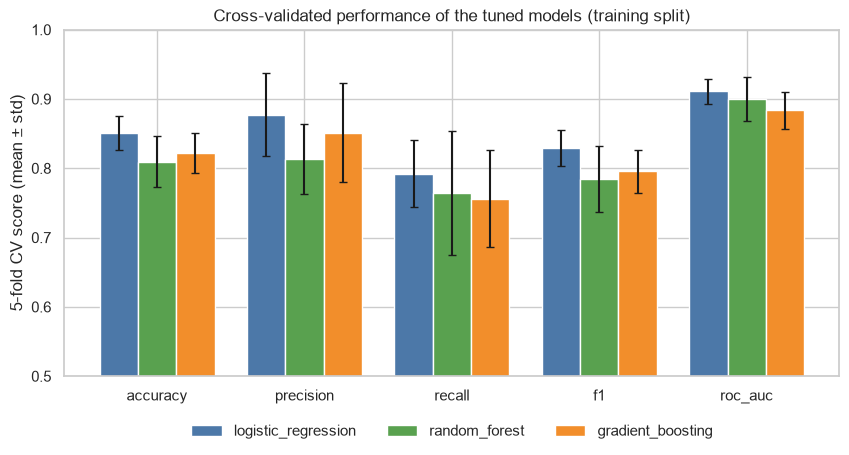

In [9]:
real = [m for m in tuned.index if m != "baseline_majority"]
long = []
for m in real:
    for metric in METRICS:
        long.append({"model": m, "metric": metric,
                     "mean": tuned.loc[m, f"cv_{metric}_mean"], "std": tuned.loc[m, f"cv_{metric}_std"]})
long = pd.DataFrame(long)

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.26
x = np.arange(len(METRICS))
for i, m in enumerate(real):
    sub = long[long.model == m].set_index("metric").loc[METRICS]
    ax.bar(x + (i - 1) * width, sub["mean"], width, yerr=sub["std"], capsize=3,
           label=m, color=MODEL_COLORS[m])
ax.set_xticks(x, METRICS); ax.set_ylim(0.5, 1.0)
ax.set_ylabel("5-fold CV score (mean ± std)")
ax.set_title("Cross-validated performance of the tuned models (training split)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
savefig("cv_metric_comparison.png"); plt.show()

**Reading the chart.** Logistic Regression has the highest mean CV ROC-AUC *and* the smallest spread across
folds, so it is both the strongest and the most stable candidate. The differences between models are within
roughly one standard deviation, so the ensembles are not clearly worse, but they also bring no measurable gain
in exchange for being slower and harder to explain. The selected model is therefore **Logistic Regression**.

### 5b. Selection rule, over-fitting check and the engineered feature

The selection rule was fixed **before** training (`src/config.py`): rank the models by mean CV ROC-AUC; any model
within **0.01** of the best counts as equally good, and the **simplest** of those is chosen
(Logistic Regression → Random Forest → Gradient Boosting). The test set plays no part.

The table also shows the **over-fitting gap** (train-fold minus validation-fold ROC-AUC inside cross-validation)
and the best CV score each model reaches **without and with** the engineered feature.

In [10]:
cols = {"cv_roc_auc_mean": "CV ROC-AUC", "cv_train_roc_auc_mean": "train-fold ROC-AUC",
        "cv_overfit_gap": "over-fitting gap", "cv_roc_auc_without_hr_ratio": "CV without hr_pct",
        "cv_roc_auc_with_hr_ratio": "CV with hr_pct"}
summary = tuned.loc[real, list(cols)].rename(columns=cols).round(4)
summary["engineered feature kept"] = [bool(tuned.loc[m, "best_params"].get("features__add_hr_ratio")) for m in real]
display(summary)
print("Selection:", out["reason"])

,CV ROC-AUC,train-fold ROC-AUC,over-fitting gap,CV without hr_pct,CV with hr_pct,engineered feature kept
model,,,,,,
logistic_regression,0.9113,0.9258,0.0145,0.9113,0.9090,False
random_forest,0.8998,0.9569,0.0572,0.8998,0.8985,False
gradient_boosting,0.8839,0.9608,0.0769,0.8839,0.8835,False


Selection: logistic_regression has the highest CV roc_auc (0.9113)


## 6. Held-out test set evaluation

The 61 test patients were not used for training or selection, so these numbers estimate performance on new
patients. With only 61 patients each misclassification moves accuracy by ~1.6 points, so the test numbers are
noisier than the CV means.

,accuracy,precision,recall,f1,roc_auc
model,,,,,
logistic_regression,0.885,0.839,0.929,0.881,0.961
random_forest,0.885,0.839,0.929,0.881,0.955
gradient_boosting,0.902,0.867,0.929,0.897,0.960
baseline_majority,0.541,0.000,0.000,0.000,0.500


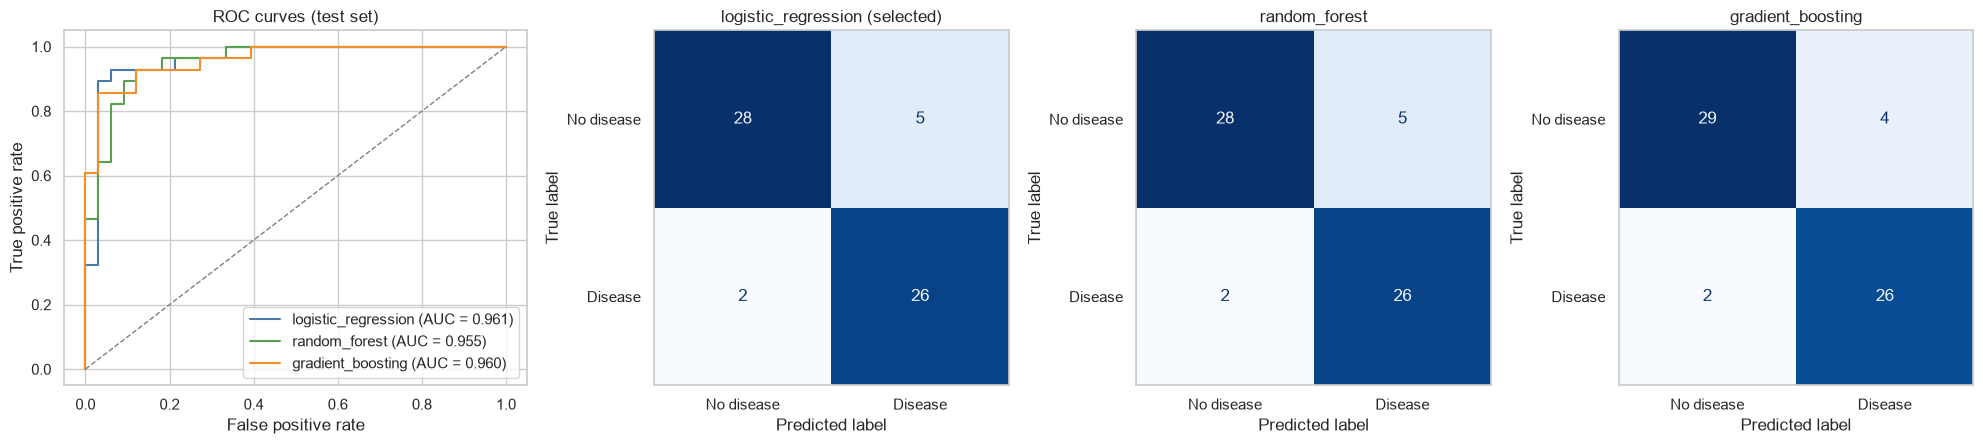

Classification report – logistic_regression (test set)
              precision    recall  f1-score   support

  No disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [11]:
test_cols = [f"test_{m}" for m in METRICS]
display(tuned.loc[real + ["baseline_majority"], test_cols].round(3)
        .rename(columns=lambda c: c.replace("test_", "")))

from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay, classification_report
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
for m in real:
    p = fitted[m].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[m], label=f"{m} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", lw=1); axes[0].set_title("ROC curves (test set)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(loc="lower right")
for ax, m in zip(axes[1:], real):
    ConfusionMatrixDisplay.from_estimator(fitted[m], X_test, y_test, display_labels=evaluate.CLASS_NAMES,
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(m + (" (selected)" if m == best_name else "")); ax.grid(False)
plt.tight_layout(); savefig("test_roc_and_confusion.png"); plt.show()

print(f"Classification report – {best_name} (test set)")
print(classification_report(y_test, fitted[best_name].predict(X_test), target_names=evaluate.CLASS_NAMES))

## 7. What drives the predictions

For Logistic Regression the **signed coefficients** (on standardised / one-hot features) show both the strength and
the direction of each effect. Random Forest importances are shown for comparison: if two very different model
families agree on the important features, that is evidence the signal is real and not an artefact of one model.

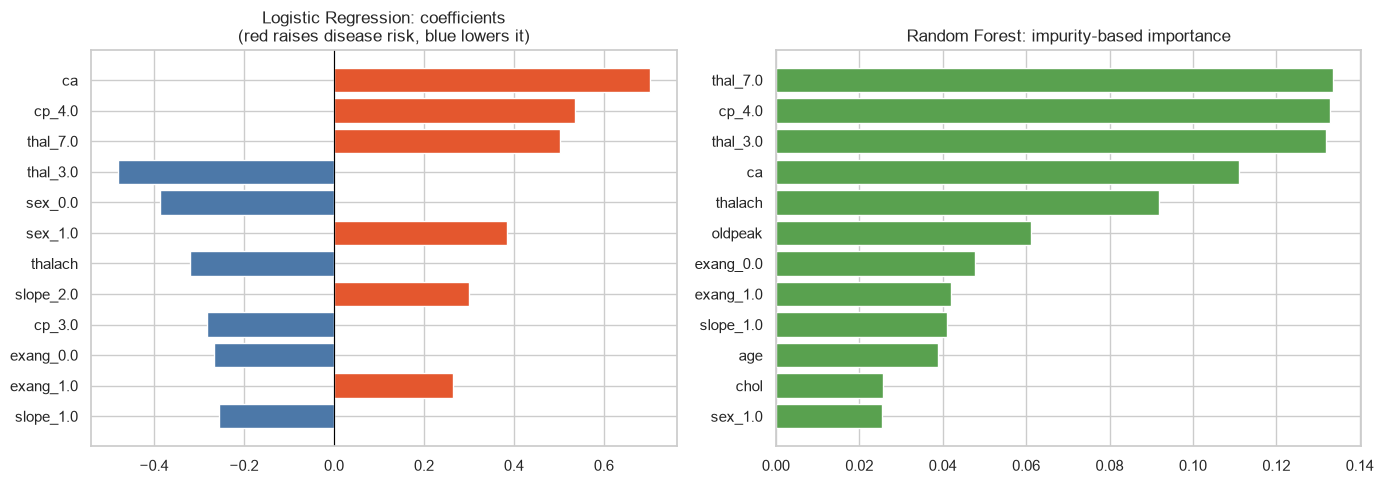

In [12]:
lr = fitted["logistic_regression"]
coef = pd.Series(lr.named_steps["model"].coef_.ravel(),
                 index=[n.split("__", 1)[1] for n in lr.named_steps["preprocess"].get_feature_names_out()])
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)[::-1]
rf_imp = evaluate.feature_importance(fitted["random_forest"]).head(12)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top.index, top.values, color=np.where(top.values > 0, "#E4572E", "#4C78A8"))
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Logistic Regression: coefficients\n(red raises disease risk, blue lowers it)")
axes[1].barh(rf_imp.index, rf_imp.values, color="#59A14F")
axes[1].set_title("Random Forest: impurity-based importance")
plt.tight_layout(); savefig("feature_drivers.png"); plt.show()

Both models put `ca` (number of blocked vessels), `thal`, chest-pain type `cp` and `thalach` near the top, and
`exang` / `slope` also appear in both lists. This matches the EDA (section 2.9 of notebook 01). `oldpeak` ranks high
for the forest but lower for the linear model, most likely because its information overlaps with `slope` and `exang`. Asymptomatic chest pain (`cp_4.0`) and reversible thal defect
(`thal_7.0`) raise the predicted risk; a normal thal result (`thal_3.0`) and a high maximum heart rate lower it.
`fbs` and `chol`, which looked weak in the EDA, contribute little here as well.

## 8. Decision threshold

The model outputs a probability; the API turns it into a label with a threshold of 0.5. In screening, a missed
disease case (false negative) is usually worse than a false alarm, so it is useful to see how precision and
recall move with the threshold.

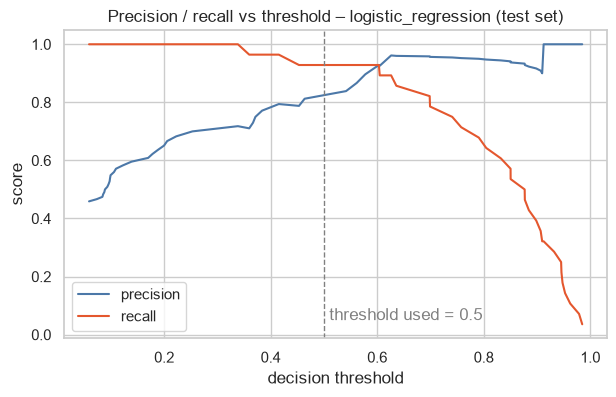

threshold 0.3: recall 1.000  precision 0.718  accuracy 0.820
threshold 0.4: recall 0.964  precision 0.794  accuracy 0.869
threshold 0.5: recall 0.929  precision 0.839  accuracy 0.885
threshold 0.6: recall 0.929  precision 0.929  accuracy 0.934


In [13]:
from sklearn.metrics import precision_recall_curve
proba = fitted[best_name].predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, prec[:-1], label="precision", color="#4C78A8")
ax.plot(thr, rec[:-1], label="recall", color="#E4572E")
ax.axvline(0.5, ls="--", color="grey", lw=1); ax.text(0.51, 0.05, "threshold used = 0.5", color="grey")
ax.set_xlabel("decision threshold"); ax.set_ylabel("score"); ax.legend()
ax.set_title(f"Precision / recall vs threshold – {best_name} (test set)")
savefig("threshold_tradeoff.png"); plt.show()

for t in (0.3, 0.4, 0.5, 0.6):
    pred = (proba >= t).astype(int)
    m = evaluate.classification_metrics(y_test, pred, proba)
    print(f"threshold {t:.1f}: recall {m['recall']:.3f}  precision {m['precision']:.3f}  accuracy {m['accuracy']:.3f}")

At 0.5 the selected model already finds most disease cases on the test set. The threshold is kept at 0.5 for the
assignment, but it is a single, documented parameter (`threshold` in `src/predict.py`) that a clinical team could
lower to favour recall.

## 9. Experiment tracking with MLflow (Task 3)

Each call of `src.train` creates one **parent run** (data hash, split settings, comparison table, ROC plot,
selected model) and one **nested run per candidate** holding:

* **parameters**: model type, best hyper-parameters, number of grid combinations;
* **metrics**: CV mean and std for 5 metrics, plus the same 5 metrics on the test set;
* **artifacts**: full `cv_results` table, confusion matrix, feature-importance plot, and the fitted pipeline with
  its input signature and an input example;
* the **dataset** used (name, source path, digest) via `mlflow.log_input`.

The best model is registered in the **Model Registry** with the alias `champion`.
To open the UI (from the repo root): `mlflow ui --backend-store-uri sqlite:///mlflow.db` → http://127.0.0.1:5000

In [14]:
import mlflow
from mlflow.tracking import MlflowClient
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)

runs = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT],
                          order_by=["attributes.start_time DESC"])
cols = ["tags.mlflow.runName", "tags.mlflow.parentRunId", "params.model_type",
        "metrics.cv_roc_auc_mean", "metrics.test_roc_auc", "metrics.test_accuracy"]
latest_parent = runs[runs["tags.mlflow.parentRunId"].isna()].iloc[0]["run_id"]
print("Latest parent run:", latest_parent)
display(runs[runs["tags.mlflow.parentRunId"] == latest_parent][cols[0:1] + cols[2:]].round(4))

client = MlflowClient()
champ = client.get_model_version_by_alias(config.REGISTERED_MODEL_NAME, "champion")
print(f"Registry: {config.REGISTERED_MODEL_NAME} version {champ.version} is @champion (run {champ.run_id[:8]}…)")

Latest parent run: 1ca7731e6eb44d22b33de9842949add4


,tags.mlflow.runName,params.model_type,metrics.cv_roc_auc_mean,metrics.test_roc_auc,metrics.test_accuracy
0,gradient_boosting,GradientBoostingClassifier,0.8839,0.9600,0.9016
1,random_forest,RandomForestClassifier,0.8998,0.9545,0.8852
2,logistic_regression,LogisticRegression,0.9113,0.9610,0.8852
3,baseline_majority,DummyClassifier,0.5000,0.5000,0.5410


Registry: heart-disease-classifier version 4 is @champion (run 36ccfd35…)


**Opening the MLflow UI.** From the project root run `mlflow ui --backend-store-uri sqlite:///mlflow.db` and open http://127.0.0.1:5000 to browse experiments, runs, artifacts and the Model Registry.

## 10. Packaged model (Task 4 preview)

The selected pipeline is saved in two formats:

* `models/heart_disease_model.joblib` – loaded by the API (`src/predict.py`);
* `models/mlflow_model/` – MLflow format (skops-serialised, with `MLmodel`, `requirements.txt`, `conda.yaml`,
  input signature), loadable with `mlflow.pyfunc.load_model`;

plus `models/model_metadata.json`, a small model card (parameters, metrics, data hash, library versions).
Below, the saved files are reloaded **from disk** and used on a raw patient record, exactly as the API will do.

In [15]:
from src.predict import load_model, predict, SAMPLE_PATIENT

meta = json.loads(config.MODEL_METADATA_PATH.read_text())
print(json.dumps({k: meta[k] for k in ["model_name", "best_params", "test_metrics", "sklearn_version"]}, indent=2))

model = load_model.__wrapped__(str(config.MODEL_PATH))     # fresh load, no cache
print("\nSample patient:", SAMPLE_PATIENT)
print("joblib model ->", predict(SAMPLE_PATIENT, model=model))

incomplete = {**SAMPLE_PATIENT, "ca": None, "thal": None}  # imputers inside the pipeline handle gaps
print("missing ca/thal ->", predict(incomplete, model=model))

pyfunc = mlflow.pyfunc.load_model(str(config.MLFLOW_MODEL_DIR))
print("MLflow-format model, class prediction ->", pyfunc.predict(X_test.head(3)), "| true:", y_test.head(3).tolist())

{
  "model_name": "logistic_regression",
  "best_params": {
    "add_hr_ratio": false,
    "C": 0.1,
    "class_weight": null,
    "l1_ratio": 0.0
  },
  "test_metrics": {
    "test_accuracy": 0.8852,
    "test_precision": 0.8387,
    "test_recall": 0.9286,
    "test_f1": 0.8814,
    "test_roc_auc": 0.961
  },
  "sklearn_version": "1.9.1"
}

Sample patient: {'age': 63, 'sex': 1, 'cp': 1, 'trestbps': 145, 'chol': 233, 'fbs': 1, 'restecg': 2, 'thalach': 150, 'exang': 0, 'oldpeak': 2.3, 'slope': 3, 'ca': 0, 'thal': 6}
joblib model -> [{'prediction': 0, 'label': 'No heart disease', 'probability_disease': 0.3814, 'confidence': 0.6186}]
missing ca/thal -> [{'prediction': 0, 'label': 'No heart disease', 'probability_disease': 0.2806, 'confidence': 0.7194}]
MLflow-format model, class prediction -> [0 1 0] | true: [0, 0, 0]


## 11. Conclusions

* **Features:** 13 raw clinical features → 25 model features (scaled numerics + one-hot categoricals), with imputation
  learned inside the pipeline. The engineered `hr_pct_predicted` feature separates the classes on its own, but the
  grid search shows it adds nothing once `thalach` and `age` are already in the model, so it is used only where it
  improves the CV score (see section 5b) – an evidence-based decision rather than an assumption.
* **Models:** three tuned classifiers plus a majority baseline were compared with 5-fold stratified CV.
  All real models beat the baseline by a wide margin (CV ROC-AUC ≈ 0.88–0.91 vs 0.50).
* **Selection:** **Logistic Regression** (L2 / ridge penalty, `C = 0.1`) has the best and most stable CV ROC-AUC and the
  smallest over-fitting gap, and the pre-declared rule selects it. It is also the simplest,
  fastest and most interpretable model, which matters for a clinical use-case and for a lightweight API container.
* **Test set:** on the 61 unseen patients the selected model reaches accuracy 0.885, recall 0.929 and ROC-AUC 0.961.
  This is slightly *higher* than the CV estimate (ROC-AUC 0.911 ± 0.018), which is expected noise for such a small test
  set; the CV figure is the more reliable estimate to quote. Either way, there is no sign of over-fitting.
* **Tracking & packaging:** every run is reproducible from `python -m src.train`; parameters, metrics, plots and models
  are in MLflow, and the champion model is registered and saved to `models/` for the API, CI and Docker steps.